# The Rhone cavity: a former water pocket rupture?

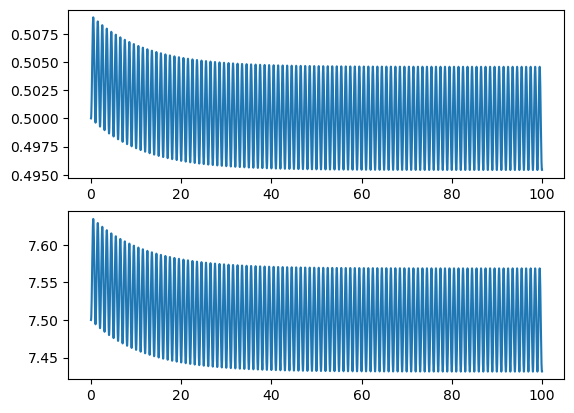

1-element Array{PyCall.PyObject,1}:
 PyObject <matplotlib.lines.Line2D object at 0x00000000018DF438>

In [2]:
dh = 0.02
V = 5000
A = V/dh

day = 3600*24

α = 5
β = 1.5*α
ω = 2*pi/day



# from year 2021
# factor 100 to convert from mBar to mH2O
a = 3/0.2 #0.18*10000
b = 0 # 148/100


# from year 2022
# factor 100 to convert from mBar to mH2O
a = 100/0.044
b = 0 #here we will still need to implement a lower bound, because discharge is not 0 at night. 
#And the amplitude matter when implementing the water pocket input



Qin(t) = α*sin(ω*t) + β
Qout(h) = a*h + b

dhdt(h, t) = Qin(t)/A - Qout(h)/A

h0 = 0.5
dt = 60
tspan = (0, 100*day)
tsteps = tspan[1]:dt:tspan[2]
h = zeros(length(tsteps))
h[1] = h0

for (i,t) in enumerate(tsteps[2:end])
    h[i+1] = h[i] + dhdt(h[i], t)
end

using PyPlot
subplot(2,1,1)
plot(tsteps/day, h)
subplot(2,1,2)
plot(tsteps/day, Qout.(h))